# M2 MALIA - Deep Learning
## Projet HAR : Étude progressive des réseaux de neurones
### Version 2 : Réseau Profond, Régularisation, Interprétabilité & Évaluation Finale

**Auteurs :** Madjiguène FALL & Alioune DIOP
**Enseignant :** Walid Bechkit — Université Lumière Lyon 2
**Année universitaire :** 2026–2027

---
### Objectifs de cette Version 2 :
1. **Extension de l'architecture (Partie 3)** : largeur (64, 128, 256) et profondeur (1 à 4 couches cachées),
   nombre de paramètres et temps de calcul.
2. **Régularisation (Partie 4)** : Dropout (p = 0,1 / 0,3 / 0,5), Weight Decay (L2), Batch Normalization, Early
   Stopping ; sélection des 2 meilleures configurations sur la validation.
3. **Courbes d'apprentissage (Partie 5.1)** de la configuration retenue.
4. **Interprétabilité (Partie 6)** : t-SNE des variables brutes et de la dernière couche cachée (sur la validation).
5. **Ouverture (Partie 7)** : étude d'ablation par famille de capteurs.
6. **Évaluation finale (Partie 5.2)** : passage **unique** sur `test.csv`, à la toute fin, et matrice de confusion.

Les comparaisons importantes (architectures, régularisations) sont répétées sur **3 graines** (42, 123, 999).

## 1. Imports des bibliothèques

In [1]:
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.optim as optim

sys.path.append('../../src')
from data_loader import load_har_data, split_by_subject, prepare_features_and_labels, create_dataloaders

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

FIG_DIR = '../../reports/figures'
RES_DIR = '../../reports/results'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

SEEDS = [42, 123, 999]
EPOCHS_ARCH, EPOCHS_REG, PATIENCE = 25, 30, 7
if os.environ.get('HAR_FAST') == '1':       # uniquement pour un test rapide du notebook
    EPOCHS_ARCH, EPOCHS_REG = 3, 3

results = {}

## 2. Chargement des Données et DataLoaders
Même découpage que la Version 1 : les volontaires 1, 3, 5 et 7 forment la validation. Le jeu de test n'est utilisé
qu'en section 9.

In [2]:
train_df, test_df = load_har_data('../../data/HAR')
train_split, val_split = split_by_subject(train_df, val_subjects=[1, 3, 5, 7])

X_tr, y_tr, le, feature_cols = prepare_features_and_labels(train_split)
X_val, y_val, _, _ = prepare_features_and_labels(val_split, label_encoder=le)
CLASSES = list(le.classes_)

batch_size = 64
train_loader, val_loader = create_dataloaders(X_tr, y_tr, X_val, y_val, batch_size=batch_size)

print(f"Échantillons d'entraînement : {len(X_tr)}")
print(f"Échantillons de validation   : {len(X_val)}")
print(f"Classes d'activité           : {CLASSES}")

Échantillons d'entraînement : 6054
Échantillons de validation   : 1298
Classes d'activité           : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


## 3. Définition de l'Architecture Profonde Modulaire (Parties 3 & 4)

In [3]:
class DeepMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dims=[128, 64], num_classes=6,
                 activation='relu', dropout_p=0.0, use_bn=False):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            if use_bn:
                layers.append(nn.BatchNorm1d(h_dim))
            if activation == 'relu':
                layers.append(nn.ReLU())
            elif activation == 'tanh':
                layers.append(nn.Tanh())
            elif activation == 'sigmoid':
                layers.append(nn.Sigmoid())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            prev_dim = h_dim
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(prev_dim, num_classes)

    def forward(self, x):
        return self.classifier(self.features(x))

    def extract_features(self, x):
        """Représentation de la dernière couche cachée (pour la t-SNE)."""
        return self.features(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

m_check = DeepMLP(hidden_dims=[256, 128, 64], dropout_p=0.3, use_bn=True)
print(m_check)
print(f"Paramètres entraînables : {count_parameters(m_check):,}")

DeepMLP(
  (features): Sequential(
    (0): Linear(in_features=561, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
  )
  (classifier): Linear(in_features=64, out_features=6, bias=True)
)
Paramètres entraînables : 186,310


## 4. Fonctions d'Entraînement avec Early Stopping
`train_model` arrête l'entraînement quand la perte de validation ne s'améliore plus pendant `patience` époques, et
**restaure les poids de la meilleure époque**. Les scores rapportés sont ceux de ce modèle restauré.

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x_b, y_b in dataloader:
        optimizer.zero_grad()
        out = model(x_b)
        loss = criterion(out, y_b)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x_b.size(0)
        correct += (out.argmax(dim=1) == y_b).sum().item()
        total += x_b.size(0)
    return total_loss / total, correct / total

def evaluate(model, dataloader, criterion):
    model.eval()
    total_loss, all_preds, all_targets = 0.0, [], []
    with torch.no_grad():
        for x_b, y_b in dataloader:
            out = model(x_b)
            total_loss += criterion(out, y_b).item() * x_b.size(0)
            all_preds.extend(out.argmax(dim=1).cpu().numpy())
            all_targets.extend(y_b.cpu().numpy())
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return total_loss / len(all_targets), acc, macro_f1, all_preds, all_targets

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=30, patience=PATIENCE):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    best_loss, best_state, patience_cnt = float('inf'), None, 0
    start = time.time()
    for ep in range(epochs):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        vl_loss, vl_acc, vl_f1, _, _ = evaluate(model, val_loader, criterion)
        for k, v in zip(history, [tr_loss, vl_loss, tr_acc, vl_acc, vl_f1]):
            history[k].append(v)
        if vl_loss < best_loss:
            best_loss, patience_cnt = vl_loss, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    history['best_epoch'] = int(np.argmin(history['val_loss'])) + 1
    return model, history, time.time() - start

def run_config(hidden_dims, activation='relu', dropout_p=0.0, use_bn=False, l2=0.0, epochs=30, seed=42,
               loaders=None, input_dim=561):
    """Entraîne une configuration pour une graine ; renvoie le modèle restauré, l'historique et les scores de validation."""
    tl, vl = loaders if loaders is not None else (train_loader, val_loader)
    set_seed(seed)
    model = DeepMLP(input_dim=input_dim, hidden_dims=hidden_dims, activation=activation, dropout_p=dropout_p, use_bn=use_bn)
    opt = optim.Adam(model.parameters(), lr=0.001, weight_decay=l2)
    model, hist, duration = train_model(model, tl, vl, nn.CrossEntropyLoss(), opt, epochs=epochs)
    vl_loss, vl_acc, vl_f1, _, _ = evaluate(model, vl, nn.CrossEntropyLoss())
    tr_acc = evaluate(model, tl, nn.CrossEntropyLoss())[1]
    return model, hist, {'val_loss': vl_loss, 'val_acc': vl_acc, 'val_f1': vl_f1, 'train_acc': tr_acc, 'time': duration}

def ms(values):
    return float(np.mean(values)), float(np.std(values, ddof=1))

## 5. Extension de l'Architecture : Largeur & Profondeur (Partie 3)
Toutes les architectures sont entraînées avec Adam (lr = 0,001, valeur retenue en V1 pour Adam ou à reprendre depuis
`reports/results/v1_results.json`), avec early stopping, sur 3 graines.

1 couche (64) [V1]               |  36,358 param. | Val Acc 96.05 ± 0.12 | Val F1 95.87 ± 0.11 | écart train-val 2.24 pt | 8.0 s


1 couche (128)                   |  72,710 param. | Val Acc 95.99 ± 0.23 | Val F1 95.80 ± 0.25 | écart train-val 2.24 pt | 8.7 s


1 couche (256)                   | 145,414 param. | Val Acc 95.69 ± 0.23 | Val F1 95.49 ± 0.24 | écart train-val 2.33 pt | 7.2 s


2 couches [128, 64]              |  80,582 param. | Val Acc 95.69 ± 0.20 | Val F1 95.50 ± 0.23 | écart train-val 2.55 pt | 8.5 s


3 couches [256, 128, 64] (ReLU)  | 185,414 param. | Val Acc 95.56 ± 0.35 | Val F1 95.36 ± 0.35 | écart train-val 2.91 pt | 11.1 s


3 couches [256, 128, 64] (Tanh)  | 185,414 param. | Val Acc 95.51 ± 0.66 | Val F1 95.30 ± 0.67 | écart train-val 2.74 pt | 9.6 s


4 couches [256, 128, 64, 32]     | 187,302 param. | Val Acc 95.71 ± 0.27 | Val F1 95.51 ± 0.27 | écart train-val 2.33 pt | 11.5 s


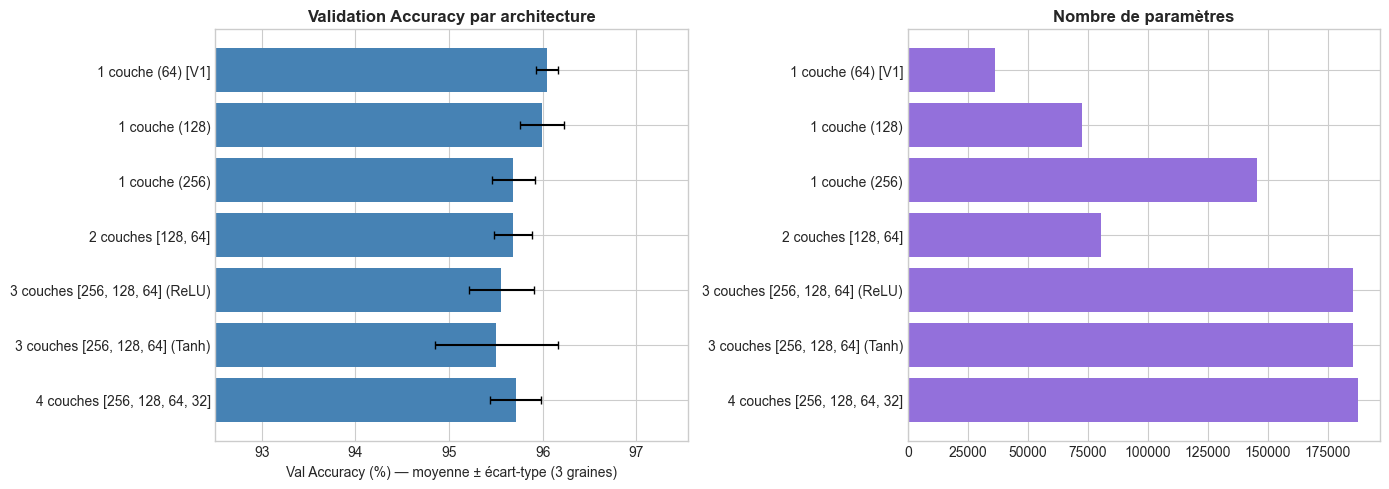

In [5]:
arch_configs = [
    ('1 couche (64) [V1]', [64], 'relu'),
    ('1 couche (128)', [128], 'relu'),
    ('1 couche (256)', [256], 'relu'),
    ('2 couches [128, 64]', [128, 64], 'relu'),
    ('3 couches [256, 128, 64] (ReLU)', [256, 128, 64], 'relu'),
    ('3 couches [256, 128, 64] (Tanh)', [256, 128, 64], 'tanh'),
    ('4 couches [256, 128, 64, 32]', [256, 128, 64, 32], 'relu'),
]
arch_rows = []
for name, dims, act in arch_configs:
    runs = [run_config(dims, act, epochs=EPOCHS_ARCH, seed=s)[2] for s in SEEDS]
    n_params = count_parameters(DeepMLP(hidden_dims=dims, activation=act))
    row = {'Architecture': name, 'Paramètres': n_params}
    for k in ['val_acc', 'val_f1', 'train_acc', 'time', 'val_loss']:
        row[k] = ms([r[k] for r in runs])
    arch_rows.append(row)
    print(f"{name:32s} | {n_params:7,d} param. | Val Acc {row['val_acc'][0]*100:.2f} ± {row['val_acc'][1]*100:.2f} "
          f"| Val F1 {row['val_f1'][0]*100:.2f} ± {row['val_f1'][1]*100:.2f} "
          f"| écart train-val {(row['train_acc'][0]-row['val_acc'][0])*100:.2f} pt | {row['time'][0]:.1f} s")

df_arch = pd.DataFrame([{'Architecture': r['Architecture'], 'acc': r['val_acc'][0] * 100, 'err': r['val_acc'][1] * 100,
                         'Paramètres': r['Paramètres']} for r in arch_rows])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(df_arch['Architecture'], df_arch['acc'], xerr=df_arch['err'], color='steelblue', capsize=3)
axes[0].set_xlim(max(0, df_arch['acc'].min() - 3), min(100, df_arch['acc'].max() + 1.5))
axes[0].invert_yaxis(); axes[0].set_xlabel("Val Accuracy (%) — moyenne ± écart-type (3 graines)")
axes[0].set_title("Validation Accuracy par architecture", fontweight='bold')
axes[1].barh(df_arch['Architecture'], df_arch['Paramètres'], color='mediumpurple')
axes[1].invert_yaxis(); axes[1].set_title("Nombre de paramètres", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '07_comparaison_largeur_profondeur.png'), dpi=300)
plt.show()
results['architectures'] = arch_rows

**Lecture :** comparer le gain de validation au coût en paramètres et en temps, et l'écart apprentissage − validation
(surapprentissage) quand la profondeur augmente ; ne conclure que si les écarts dépassent les écarts-types.

## 6. Régularisation et Robustesse (Partie 4)
Sur l'architecture à 3 couches [256, 128, 64] (ReLU), chaque technique est évaluée sur 3 graines ; l'early stopping
est appliqué à toutes les configurations.

Sans régularisation                  | Val Loss 0.1182 | Val Acc 95.56 ± 0.35 | Val F1 95.36 ± 0.35


Dropout (p=0.1)                      | Val Loss 0.1084 | Val Acc 95.97 ± 0.12 | Val F1 95.77 ± 0.14


Dropout (p=0.3)                      | Val Loss 0.0990 | Val Acc 96.15 ± 0.23 | Val F1 95.99 ± 0.27


Dropout (p=0.5)                      | Val Loss 0.0978 | Val Acc 96.48 ± 0.12 | Val F1 96.30 ± 0.13


Weight Decay (L2 = 1e-4)             | Val Loss 0.1184 | Val Acc 95.71 ± 0.50 | Val F1 95.51 ± 0.51


Batch Normalization                  | Val Loss 0.1453 | Val Acc 94.99 ± 0.54 | Val F1 94.78 ± 0.57


BatchNorm + Dropout 0.3              | Val Loss 0.1122 | Val Acc 95.81 ± 0.67 | Val F1 95.62 ± 0.72


BatchNorm + Dropout 0.3 + L2 (1e-4)  | Val Loss 0.1196 | Val Acc 95.81 ± 0.56 | Val F1 95.55 ± 0.64


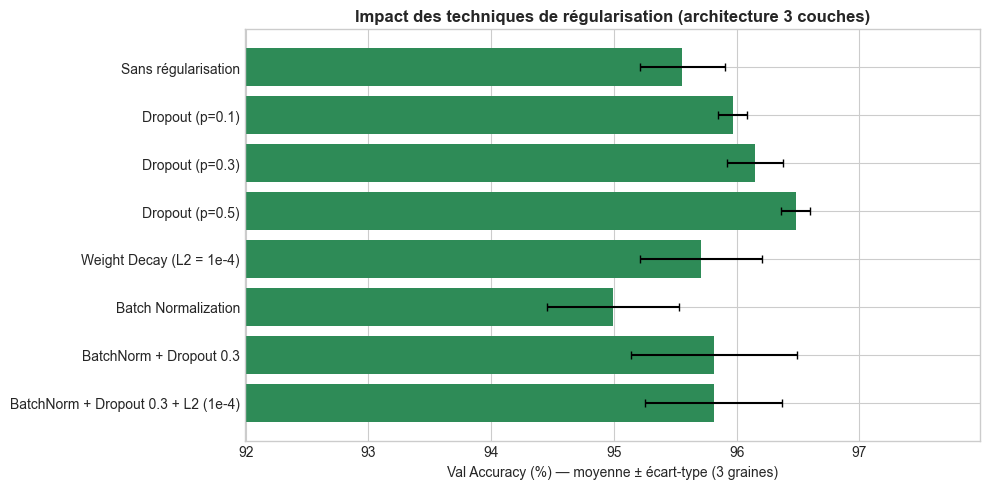

Configurations retenues : ['Dropout (p=0.5)', 'Dropout (p=0.3)']
Écart entre les deux : 0.32 pt (s1+s2 = 0.40 pt) -> non significatif


In [6]:
reg_configs = [
    ('Sans régularisation', 0.0, False, 0.0),
    ('Dropout (p=0.1)', 0.1, False, 0.0),
    ('Dropout (p=0.3)', 0.3, False, 0.0),
    ('Dropout (p=0.5)', 0.5, False, 0.0),
    ('Weight Decay (L2 = 1e-4)', 0.0, False, 1e-4),
    ('Batch Normalization', 0.0, True, 0.0),
    ('BatchNorm + Dropout 0.3', 0.3, True, 0.0),
    ('BatchNorm + Dropout 0.3 + L2 (1e-4)', 0.3, True, 1e-4),
]
reg_rows, reg_models, reg_histories = [], {}, {}
for label, drop_p, use_bn, l2 in reg_configs:
    runs = [run_config([256, 128, 64], 'relu', drop_p, use_bn, l2, epochs=EPOCHS_REG, seed=s) for s in SEEDS]
    reg_models[label] = [r[0] for r in runs]
    reg_histories[label] = runs[0][1]
    row = {'Régularisation': label, 'config': {'dropout_p': drop_p, 'use_bn': use_bn, 'l2': l2}}
    for k in ['val_loss', 'val_acc', 'val_f1', 'train_acc']:
        row[k] = ms([r[2][k] for r in runs])
    row['best_epoch'] = ms([r[1]['best_epoch'] for r in runs])
    reg_rows.append(row)
    print(f"{label:36s} | Val Loss {row['val_loss'][0]:.4f} | Val Acc {row['val_acc'][0]*100:.2f} ± {row['val_acc'][1]*100:.2f} "
          f"| Val F1 {row['val_f1'][0]*100:.2f} ± {row['val_f1'][1]*100:.2f}")

df_reg = pd.DataFrame([{'Régularisation': r['Régularisation'], 'acc': r['val_acc'][0] * 100,
                        'err': r['val_acc'][1] * 100} for r in reg_rows])
plt.figure(figsize=(10, 5))
plt.barh(df_reg['Régularisation'], df_reg['acc'], xerr=df_reg['err'], color='seagreen', capsize=3)
plt.xlim(max(0, df_reg['acc'].min() - 3), min(100, df_reg['acc'].max() + 1.5))
plt.gca().invert_yaxis()
plt.xlabel("Val Accuracy (%) — moyenne ± écart-type (3 graines)")
plt.title("Impact des techniques de régularisation (architecture 3 couches)", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '08_comparaison_regularisation.png'), dpi=300)
plt.show()

# Sélection des 2 meilleures configurations (F1 macro moyen de validation)
ranked = sorted(reg_rows, key=lambda r: -r['val_f1'][0])
selected = [r['Régularisation'] for r in ranked[:2]]
best, second = ranked[0], ranked[1]
diff, tol = best['val_f1'][0] - second['val_f1'][0], best['val_f1'][1] + second['val_f1'][1]
print("Configurations retenues :", selected)
print(f"Écart entre les deux : {diff*100:.2f} pt (s1+s2 = {tol*100:.2f} pt) -> "
      f"{'significatif' if diff > tol else 'non significatif'}")
results['regularisation'] = reg_rows
results['selection'] = selected

## 7. Courbes d'Apprentissage de la configuration retenue (Partie 5.1)

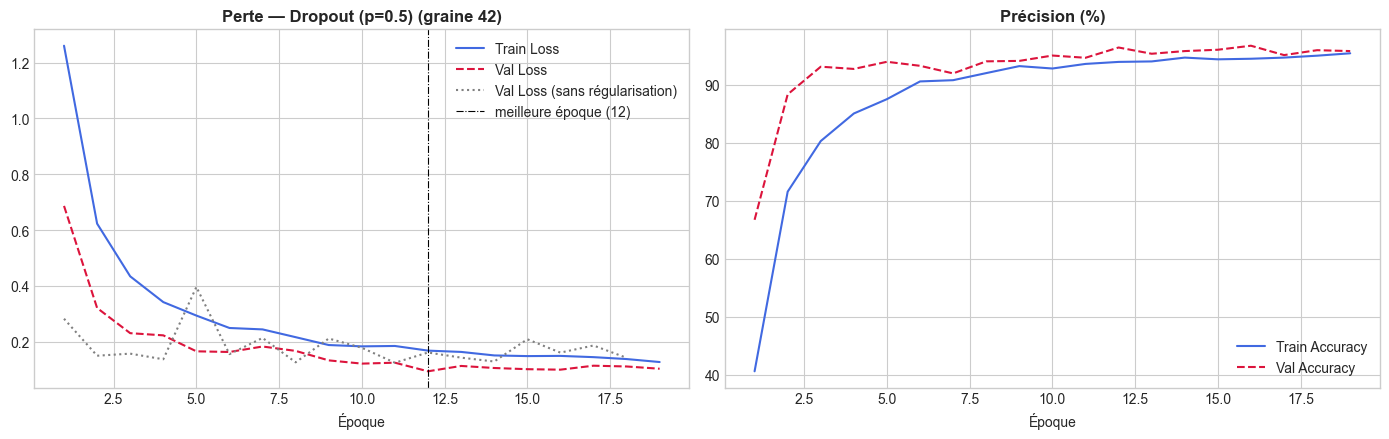

In [7]:
h = reg_histories[selected[0]]
h0 = reg_histories['Sans régularisation']
ep = range(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ep, h['train_loss'], label='Train Loss', color='royalblue')
axes[0].plot(ep, h['val_loss'], label='Val Loss', color='crimson', ls='--')
axes[0].plot(range(1, len(h0['val_loss']) + 1), h0['val_loss'], label='Val Loss (sans régularisation)', color='gray', ls=':')
axes[0].axvline(h['best_epoch'], color='k', lw=0.8, ls='-.', label=f"meilleure époque ({h['best_epoch']})")
axes[0].set_title(f"Perte — {selected[0]} (graine 42)", fontweight='bold'); axes[0].set_xlabel("Époque"); axes[0].legend()
axes[1].plot(ep, [x * 100 for x in h['train_acc']], label='Train Accuracy', color='royalblue')
axes[1].plot(ep, [x * 100 for x in h['val_acc']], label='Val Accuracy', color='crimson', ls='--')
axes[1].set_title("Précision (%)", fontweight='bold'); axes[1].set_xlabel("Époque"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '09_courbes_apprentissage_meilleur_modele.png'), dpi=300)
plt.show()

## 8. Interprétabilité et Réduction de Dimension (Partie 6)

**t-SNE** transforme les distances en probabilités de voisinage (gaussiennes dans l'espace d'origine, de largeur fixée
par la *perplexité*), puis cherche une disposition 2D (noyau de Student) qui conserve ces voisinages, en minimisant la
divergence de Kullback-Leibler. Précautions : les distances entre groupes et leurs tailles ne sont pas
interprétables, et le résultat dépend de la perplexité et de la graine.

On projette les fenêtres de **validation** (le test reste réservé à l'évaluation finale) : variables brutes
(561 dimensions) contre activations de la dernière couche cachée du modèle retenu (graine 42).

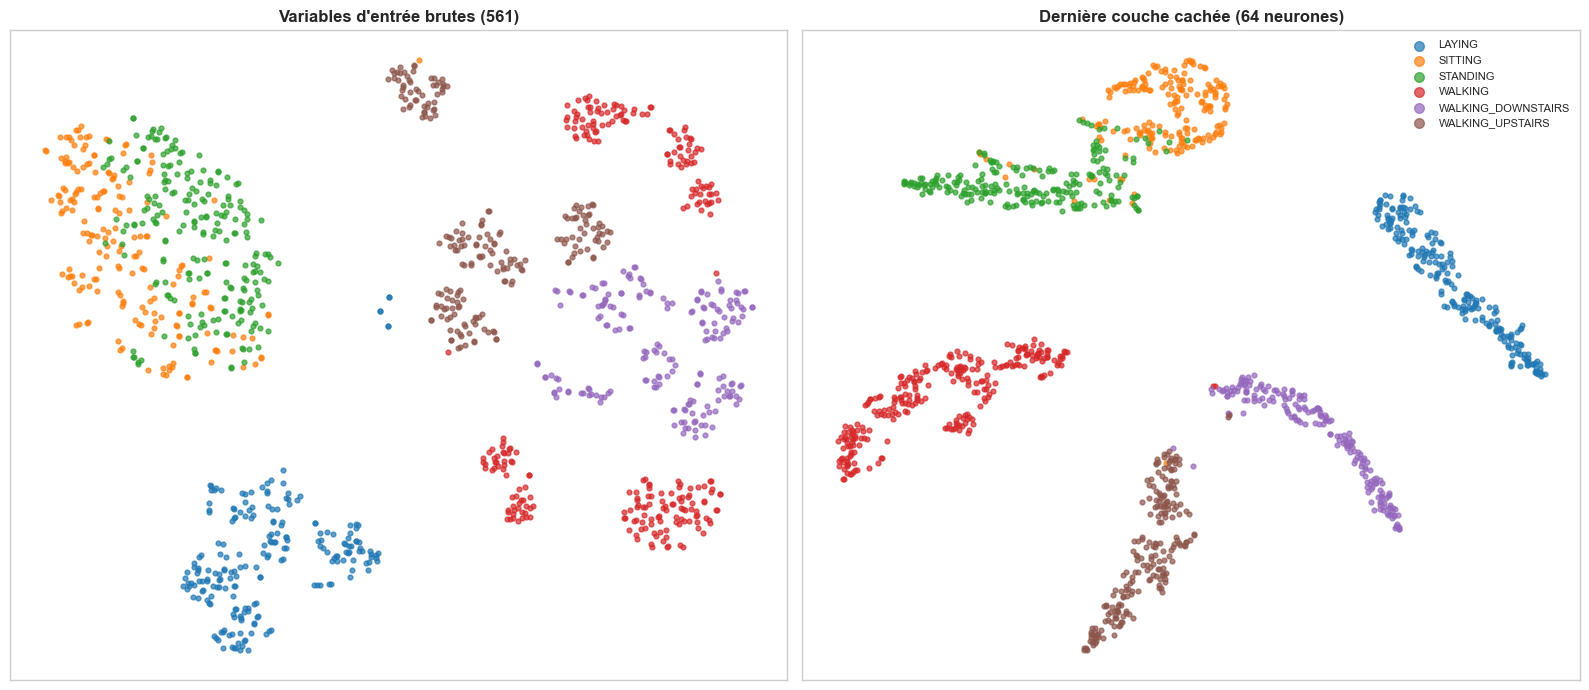

Pureté des 10 plus proches voisins : {'entrées brutes': 0.925, 'couche cachée': 0.955}


In [8]:
best_model = reg_models[selected[0]][0]
best_model.eval()
with torch.no_grad():
    latent = best_model.extract_features(torch.tensor(X_val)).cpu().numpy()

emb_raw = TSNE(n_components=2, perplexity=30, random_state=42, init='pca').fit_transform(X_val)
emb_lat = TSNE(n_components=2, perplexity=30, random_state=42, init='pca').fit_transform(latent)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
palette = sns.color_palette('tab10', len(CLASSES))
for i, act in enumerate(CLASSES):
    axes[0].scatter(emb_raw[y_val == i, 0], emb_raw[y_val == i, 1], label=act, color=palette[i], alpha=0.7, s=12)
    axes[1].scatter(emb_lat[y_val == i, 0], emb_lat[y_val == i, 1], label=act, color=palette[i], alpha=0.7, s=12)
axes[0].set_title("Variables d'entrée brutes (561)", fontweight='bold')
axes[1].set_title(f"Dernière couche cachée ({latent.shape[1]} neurones)", fontweight='bold')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(loc='best', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '11_tsne_brut_vs_latent.png'), dpi=300)
plt.show()

# Vérification chiffrée (indépendante de la figure) : part des 10 plus proches voisins de même classe
from sklearn.neighbors import NearestNeighbors
def knn_purity(Z, y, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return float((y[idx] == y[:, None]).mean())
purity = {'entrées brutes': knn_purity(X_val, y_val), 'couche cachée': knn_purity(latent, y_val)}
print("Pureté des 10 plus proches voisins :", {k: round(v, 3) for k, v in purity.items()})
results['tsne'] = {'purete_knn': purity, 'perplexite': 30}

**Sensibilité à la perplexité** (précaution d'interprétation) :

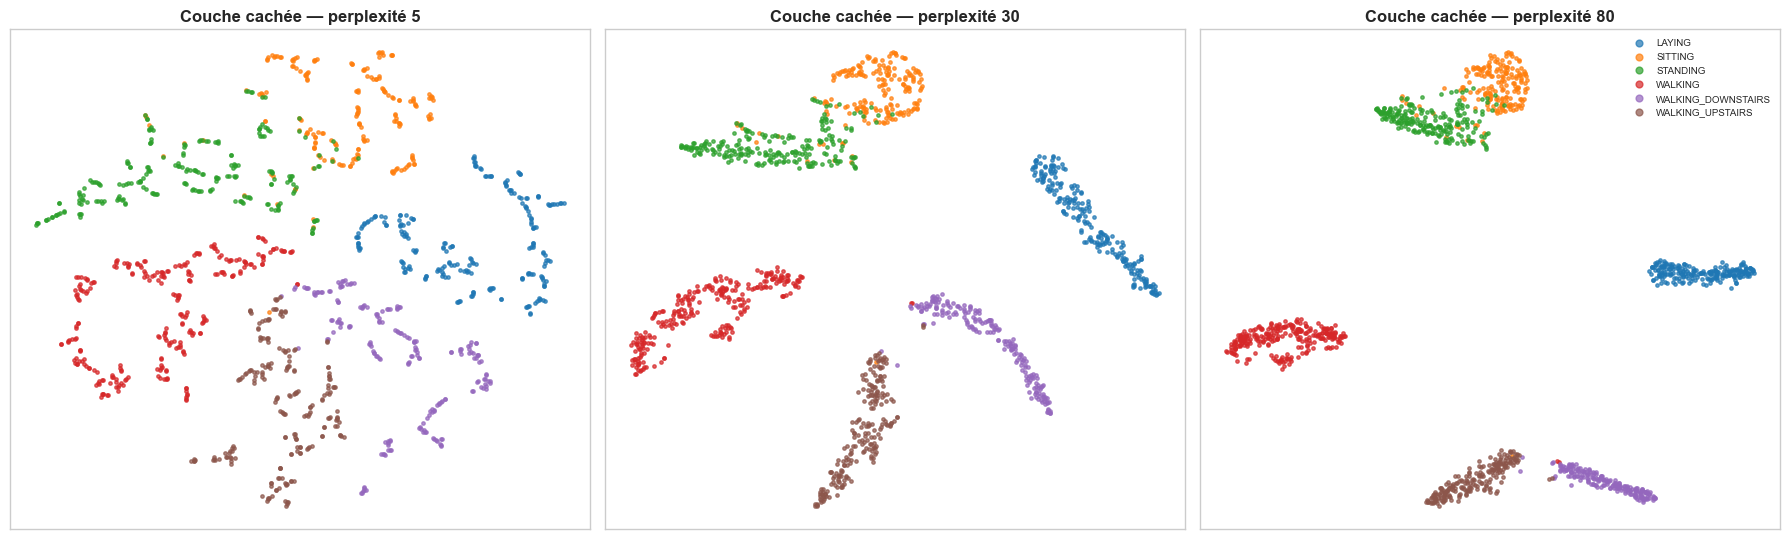

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, p in zip(axes, [5, 30, 80]):
    e = TSNE(n_components=2, perplexity=p, random_state=42, init='pca').fit_transform(latent)
    for i, act in enumerate(CLASSES):
        ax.scatter(e[y_val == i, 0], e[y_val == i, 1], color=palette[i], s=6, alpha=0.7, label=act)
    ax.set_title(f"Couche cachée — perplexité {p}", fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
axes[-1].legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '11b_tsne_perplexite.png'), dpi=300)
plt.show()

## 9. Ouverture : Étude d'Ablation par Famille de Capteurs (Partie 7)
On réentraîne un réseau [128, 64] sur des sous-ensembles de variables et l'on mesure la précision de **validation**
(une graine : étude exploratoire).

Tous les capteurs                      | 561 variables | Val Acc 95.92% | Val F1 95.75%


Sans gravité (pas de tGravity)         | 508 variables | Val Acc 93.84% | Val F1 93.59%


Sans gyroscope (accéléromètre seul)    | 348 variables | Val Acc 94.14% | Val F1 93.93%


Domaine temporel seul                  | 272 variables | Val Acc 95.30% | Val F1 95.11%


Domaine fréquentiel seul               | 289 variables | Val Acc 81.66% | Val F1 81.03%


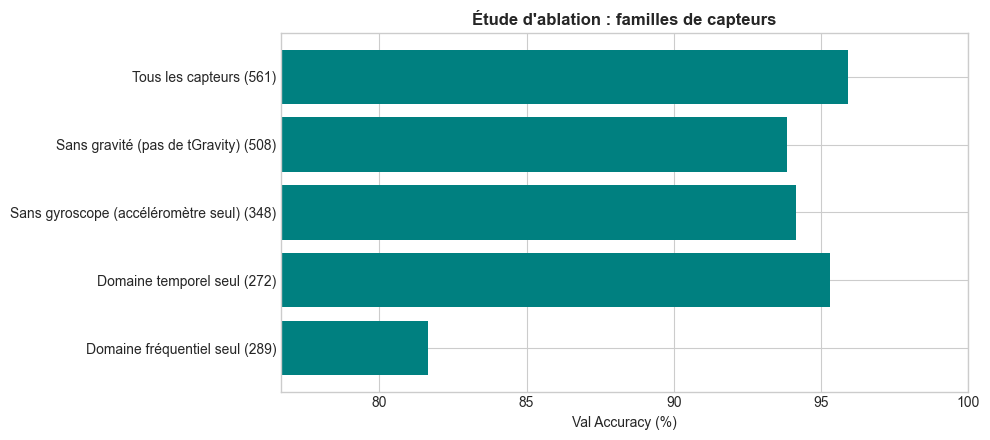

In [10]:
sensor_groups = {
    'Tous les capteurs': feature_cols,
    'Sans gravité (pas de tGravity)': [c for c in feature_cols if 'Gravity' not in c],
    'Sans gyroscope (accéléromètre seul)': [c for c in feature_cols if 'Gyro' not in c],
    'Domaine temporel seul': [c for c in feature_cols if not c.startswith('f')],
    'Domaine fréquentiel seul': [c for c in feature_cols if c.startswith('f')],
}
ablation = []
for g_name, cols in sensor_groups.items():
    idx = [feature_cols.index(c) for c in cols]
    loaders = create_dataloaders(X_tr[:, idx], y_tr, X_val[:, idx], y_val, batch_size=batch_size)
    _, _, sc = run_config([128, 64], 'relu', epochs=EPOCHS_ARCH, seed=42, loaders=loaders, input_dim=len(cols))
    ablation.append({'Groupe': g_name, 'Variables': len(cols), 'val_acc': sc['val_acc'], 'val_f1': sc['val_f1']})
    print(f"{g_name:38s} | {len(cols):3d} variables | Val Acc {sc['val_acc']*100:.2f}% | Val F1 {sc['val_f1']*100:.2f}%")

df_abl = pd.DataFrame(ablation)
plt.figure(figsize=(10, 4.5))
plt.barh(df_abl['Groupe'] + ' (' + df_abl['Variables'].astype(str) + ')', df_abl['val_acc'] * 100, color='teal')
plt.xlim(max(0, df_abl['val_acc'].min() * 100 - 5), 100)
plt.gca().invert_yaxis(); plt.xlabel("Val Accuracy (%)")
plt.title("Étude d'ablation : familles de capteurs", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '12_importance_capteurs_ablation.png'), dpi=300)
plt.show()
results['ablation'] = ablation

## 10. Évaluation Finale sur le Test (Partie 5.2) — passage unique
⚠️ Tous les choix sont figés. On évalue **une seule fois** sur `test.csv` les 2 configurations retenues, pour leurs
3 graines. La référence et le MLP à une couche ont été évalués de la même manière en fin de Version 1
(`reports/results/v1_results.json`) ; le tableau final du rapport rassemble les deux.

Dropout (p=0.5)                      | Val Acc 96.48 ± 0.12 | Test Acc 94.17 ± 0.26 | Test F1 94.13 ± 0.28


Dropout (p=0.3)                      | Val Acc 96.15 ± 0.23 | Test Acc 93.60 ± 0.36 | Test F1 93.56 ± 0.39

Rapport par classe — Dropout (p=0.5) (graine 42) :
                    precision    recall  f1-score   support

            LAYING      0.998     1.000     0.999       537
           SITTING      0.952     0.802     0.871       491
          STANDING      0.846     0.962     0.901       532
           WALKING      0.980     0.964     0.972       496
WALKING_DOWNSTAIRS      0.979     0.910     0.943       420
  WALKING_UPSTAIRS      0.906     0.985     0.944       471

          accuracy                          0.939      2947
         macro avg      0.944     0.937     0.938      2947
      weighted avg      0.943     0.939     0.939      2947



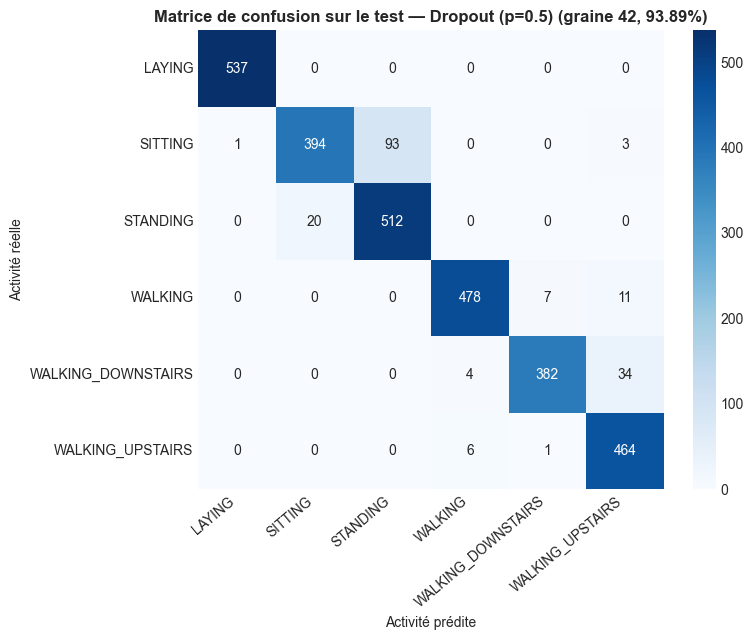

Résultats enregistrés dans reports/results/v2_results.json


In [11]:
X_test, y_test, _, _ = prepare_features_and_labels(test_df, label_encoder=le)
_, test_loader = create_dataloaders(X_tr, y_tr, X_test, y_test, batch_size=batch_size)
crit = nn.CrossEntropyLoss()

test_res = {}
for label in selected:
    evals = [evaluate(m, test_loader, crit) for m in reg_models[label]]
    row = next(r for r in reg_rows if r['Régularisation'] == label)
    test_res[label] = {'val_acc': row['val_acc'], 'val_f1': row['val_f1'],
                       'test_acc': ms([e[1] for e in evals]), 'test_f1': ms([e[2] for e in evals])}
    t = test_res[label]
    print(f"{label:36s} | Val Acc {t['val_acc'][0]*100:.2f} ± {t['val_acc'][1]*100:.2f} "
          f"| Test Acc {t['test_acc'][0]*100:.2f} ± {t['test_acc'][1]*100:.2f} "
          f"| Test F1 {t['test_f1'][0]*100:.2f} ± {t['test_f1'][1]*100:.2f}")

_, acc_best, f1_best, preds_test, targets_test = evaluate(reg_models[selected[0]][0], test_loader, crit)
print(f"\nRapport par classe — {selected[0]} (graine 42) :")
print(classification_report(targets_test, preds_test, target_names=CLASSES, digits=3))

cm = confusion_matrix(targets_test, preds_test)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f"Matrice de confusion sur le test — {selected[0]} (graine 42, {acc_best*100:.2f}%)", fontweight='bold')
plt.xlabel("Activité prédite"); plt.ylabel("Activité réelle")
plt.xticks(rotation=40, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '10_matrice_confusion_test.png'), dpi=300)
plt.show()

results['test'] = test_res
results['test_confusion'] = {'config': selected[0], 'acc': acc_best, 'f1': f1_best, 'matrice': cm.tolist(),
                             'classes': CLASSES,
                             'f1_par_classe': dict(zip(CLASSES, f1_score(targets_test, preds_test, average=None).tolist()))}
with open(os.path.join(RES_DIR, 'v2_results.json'), 'w') as f:
    json.dump(results, f, indent=2, default=float)
print("Résultats enregistrés dans reports/results/v2_results.json")

### Conclusions de la Version 2
- **Architecture :** le gain apporté par la largeur et la profondeur est à comparer aux écarts-types et au coût en
  paramètres ; un réseau plus profond surapprend plus vite (écart apprentissage − validation).
- **Régularisation :** la configuration retenue et la significativité de son avantage sont données en section 6.
- **Test :** comparer l'écart validation − test des configurations retenues, et leur score de test à celui de la
  référence (Version 1).
- **Confusions :** SITTING / STANDING concentre l'essentiel des erreurs attendues (deux postures immobiles ; le
  téléphone à la ceinture mesure surtout la gravité, d'orientation très proche).